<a href="https://colab.research.google.com/github/aditiprasannna/DLG-lab/blob/main/lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [7]:
num_notes = 50
sequence_length = 30
num_sequences = 1000

data = np.random.randint(
    0,
    num_notes,
    size=(num_sequences, sequence_length)
)

print("Dataset shape:", data.shape)

Dataset shape: (1000, 30)


In [8]:
x_train = data[:, :-1]
y_train = data[:, 1:]

NUM_CLASSES = num_notes

x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

x_train: (1000, 29, 50)
y_train: (1000, 29, 50)


In [9]:
assert x_train.shape == (1000, 29, 50)
assert y_train.shape == (1000, 29, 50)

print("Task 1 looks correct!")

Task 1 looks correct!


In [10]:
model = models.Sequential()

model.add(layers.Input(shape=(sequence_length - 1, num_notes)))

model.add(
    layers.Bidirectional(
        layers.LSTM(128, return_sequences=True)
    )
)

model.add(
    layers.Bidirectional(
        layers.LSTM(128, return_sequences=True)
    )
)

model.add(
    layers.TimeDistributed(
        layers.Dense(num_notes, activation='softmax')
    )
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 421ms/step - accuracy: 0.1008 - loss: 3.8850 - val_accuracy: 0.1593 - val_loss: 3.8452
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 273ms/step - accuracy: 0.1337 - loss: 3.7697 - val_accuracy: 0.0914 - val_loss: 3.6628
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 462ms/step - accuracy: 0.1215 - loss: 3.5145 - val_accuracy: 0.1307 - val_loss: 3.4034
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 272ms/step - accuracy: 0.1590 - loss: 3.2354 - val_accuracy: 0.1766 - val_loss: 3.1122
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 407ms/step - accuracy: 0.2068 - loss: 2.8983 - val_accuracy: 0.2350 - val_loss: 2.7432
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 271ms/step - accuracy: 0.2690 - loss: 2.5056 - val_accuracy: 0.3107 - val_loss: 2.3413
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 268ms/step - accuracy: 0.3464 - loss: 2.1085 - val_accuracy: 0.3853 - val_loss: 1.9677
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 391ms/step - accuracy: 0.4302 - loss: 1.7411 - val_accuracy: 0

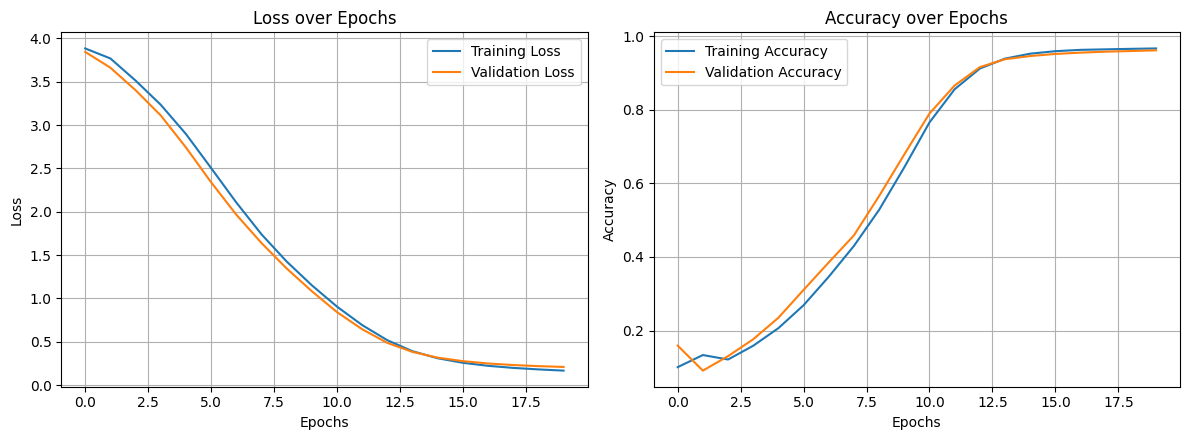

In [14]:
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [15]:
def generate_music(model, start_sequence, num_generated_notes=50):
    generated = []
    current_sequence = start_sequence.copy()

    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)

        next_note = np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        oh = to_categorical(next_note, num_classes=num_notes)
        oh = oh.reshape(1, 1, num_notes)

        current_sequence = np.concatenate(
            [current_sequence[:, 1:, :], oh],
            axis=1
        )

    return generated

In [16]:
start = np.random.randint(
    0,
    num_notes,
    size=(1, sequence_length - 1)
)

start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(
    model,
    start,
    num_generated_notes=50
)

print("Generated Music:", generated_music)

Generated Music: [28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


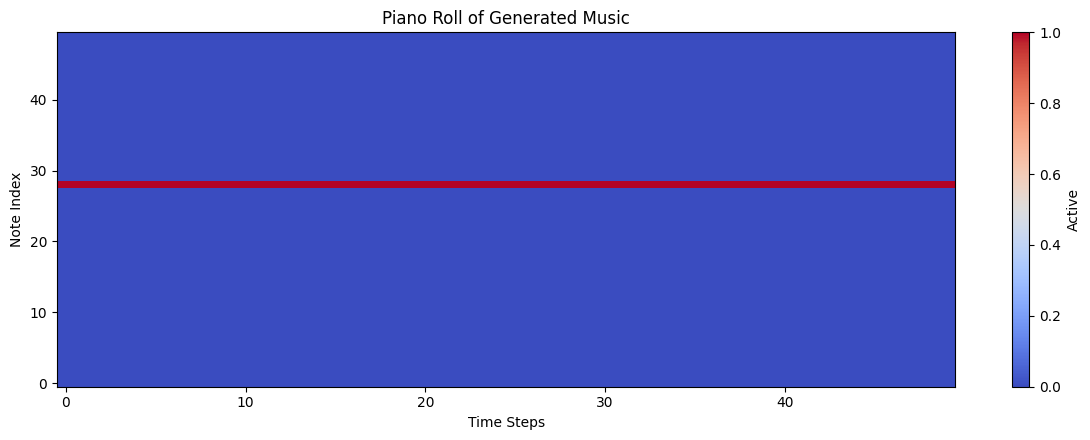

In [17]:
piano_roll = np.zeros((num_notes, len(generated_music)))

for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1

plt.figure(figsize=(12, 4.5))

plt.imshow(
    piano_roll,
    aspect='auto',
    cmap='coolwarm',
    origin='lower',
    interpolation='nearest'
)

plt.colorbar(label='Active')
plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps')
plt.ylabel('Note Index')

plt.tight_layout()
plt.show()

In [18]:
model.save("BiRNN_Music_Model.keras")

print("Model saved successfully!")

Model saved successfully!
